# Homework 4: Leg Agility Filter
## Name: Jon Knapp
### Date: October 27, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Checking my work and my logic


## Problem 1: For each of the signal, show a time domain plot with the detected maxima and minima shown by dots. If you used a filter, show the filtered signal as well as the original signal on the same plot. If you applied a simple threshold (or set of thresholds) for the detection of extrema, show these thresholds on the plot.

### PSDs for provided signals

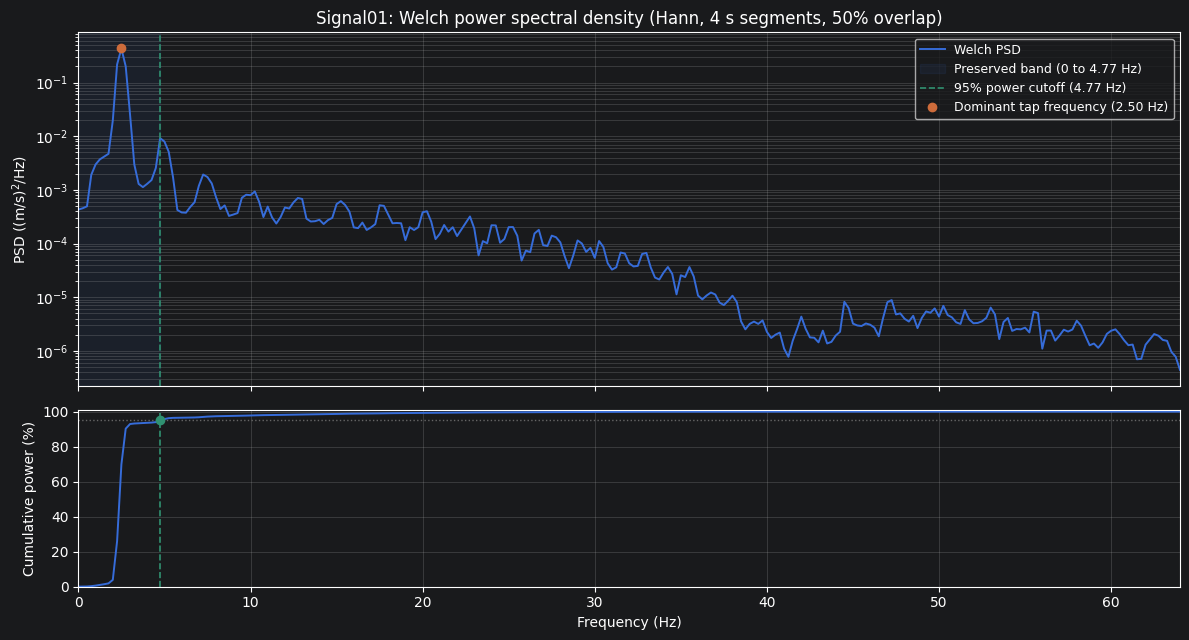

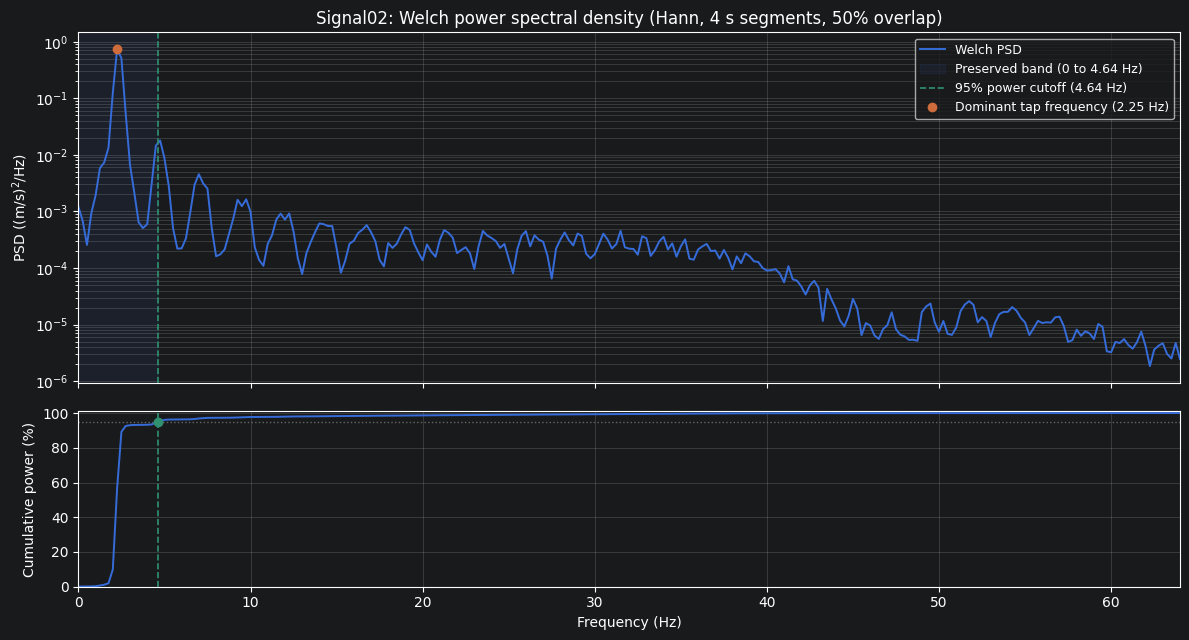

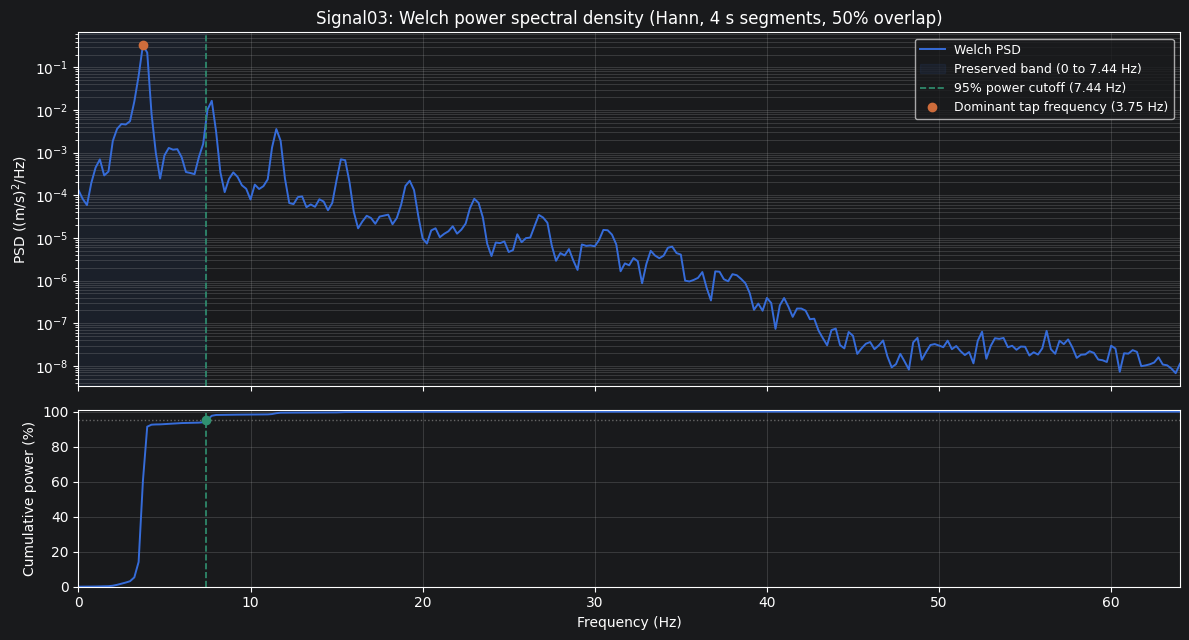

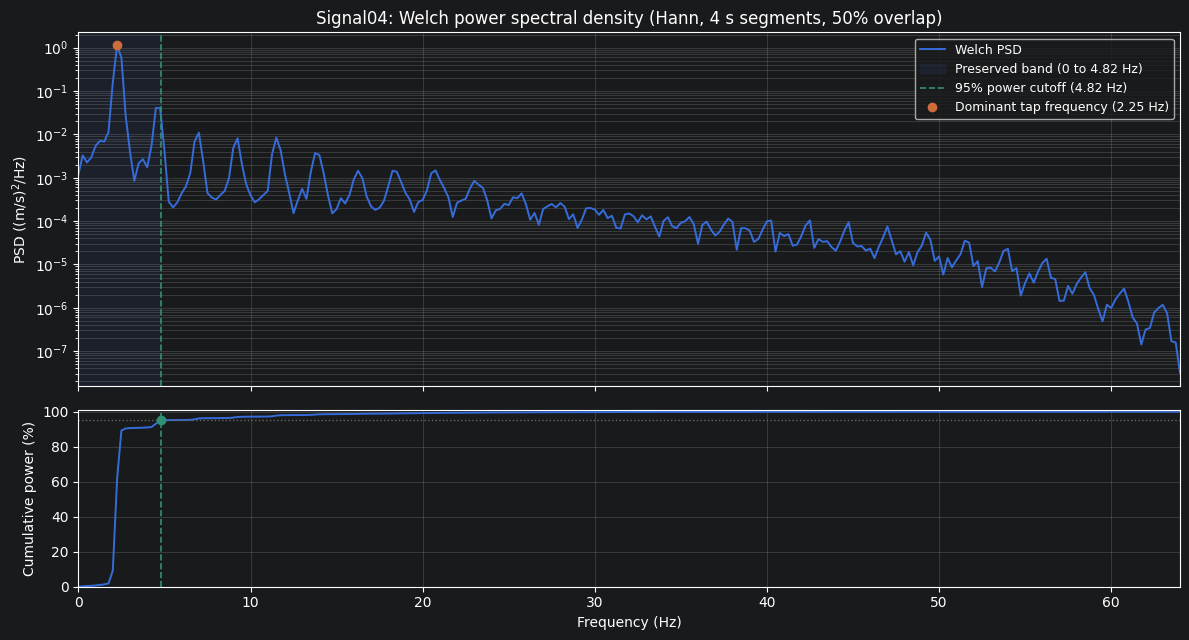

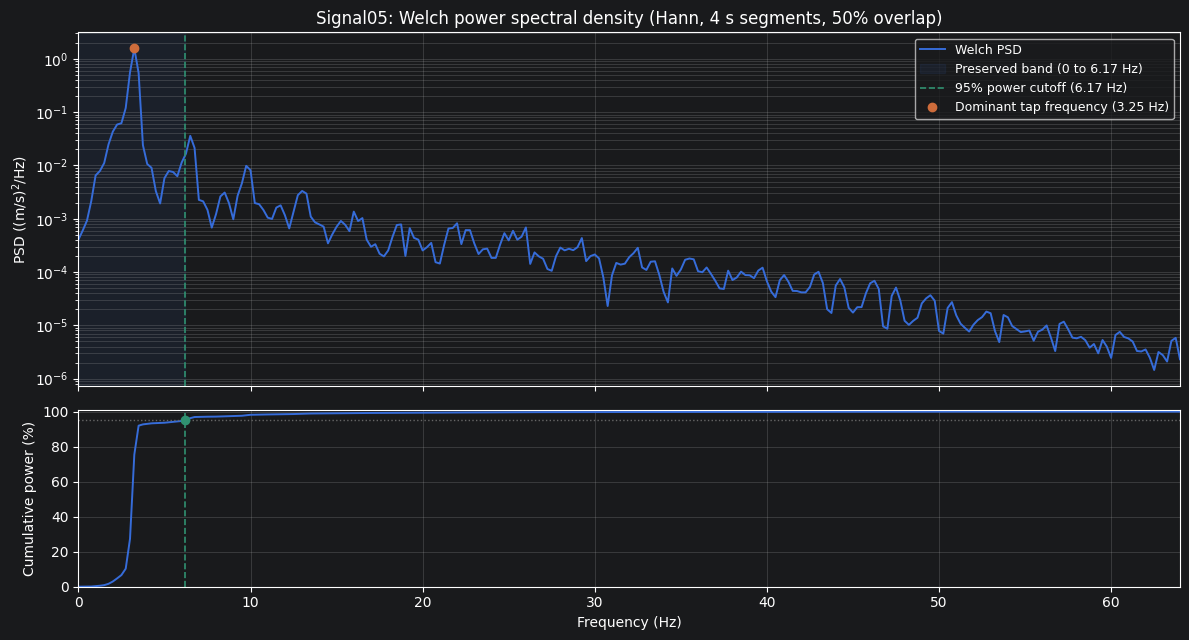

Signal       f0 (Hz)   f95 (Hz)
Signal01        2.50       4.77
Signal02        2.25       4.64
Signal03        3.75       7.44
Signal04        2.25       4.82
Signal05        3.25       6.17

95% power cutoff range: 4.64 to 7.44 Hz (mean 5.57 Hz)


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs        = 128.0                  # sample rate (Hz)
data_dir  = os.path.join('.', 'Leg Agility')
files     = [f'Signal0{k}.txt' for k in range(1, 6)]

nperseg    = 512                   # 4 s Hann segments -> 0.25 Hz resolution, 50% overlap
power_keep = 0.95                  # fraction of total power the cutoff must preserve

summary = []
for fname in files:
    x = np.loadtxt(os.path.join(data_dir, fname))
    f, P = signal.welch(x, fs=fs, window='hann', nperseg=nperseg,
                        noverlap=nperseg // 2, detrend='constant', scaling='density')

    # Dominant (tap) frequency
    k_pk = np.argmax(P)
    f_pk = f[k_pk]

    # Cumulative fraction of power from 0 Hz up to each frequency
    cum = np.cumsum(P) / P.sum()

    # Lowest frequency at which the cumulative power reaches power_keep
    # (linear interpolation between bins for sub-bin precision)
    f95 = np.interp(power_keep, cum, f)

    summary.append((fname.removesuffix('.txt'), f_pk, f95))

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                                   gridspec_kw=dict(height_ratios=[2, 1]))

    # --- Top: PSD ---
    ax1.semilogy(f, P, color='C0', lw=1.4, label='Welch PSD')
    ax1.axvspan(f[0], f95, color='C0', alpha=0.08,
                label=f'Preserved band (0 to {f95:.2f} Hz)')
    ax1.axvline(f95, color='C3', ls='--', lw=1.2,
                label=f'{100*power_keep:g}% power cutoff ({f95:.2f} Hz)')
    ax1.plot(f_pk, P[k_pk], 'o', color='C1', ms=6,
             label=f'Dominant tap frequency ({f_pk:.2f} Hz)')
    ax1.set_ylim(P.min() / 2, P.max() * 2)
    ax1.set_ylabel('PSD ((m/s)$^2$/Hz)')
    ax1.set_title(f'{fname.removesuffix(".txt")}: Welch power spectral density '
                  f'(Hann, {nperseg/fs:g} s segments, 50% overlap)')
    ax1.legend(loc='upper right', fontsize=9)
    ax1.grid(alpha=0.3, which='both')

    # --- Bottom: cumulative power ---
    ax2.plot(f, 100 * cum, color='C0', lw=1.4)
    ax2.axhline(100 * power_keep, color='0.4', ls=':', lw=1)
    ax2.axvline(f95, color='C3', ls='--', lw=1.2)
    ax2.plot(f95, 100 * power_keep, 'o', color='C3', ms=6)
    ax2.set_xlim(f[0], f[-1])
    ax2.set_ylim(0, 101)
    ax2.set_xlabel('Frequency (Hz)')
    ax2.set_ylabel('Cumulative power (%)')
    ax2.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

# Summary table of the per-signal cutoffs
print(f'{"Signal":<10}{"f0 (Hz)":>10}{"f95 (Hz)":>11}')
for name, f_pk, f95 in summary:
    print(f'{name:<10}{f_pk:>10.2f}{f95:>11.2f}')
f95_all = np.array([s[2] for s in summary])
print(f'\n95% power cutoff range: {f95_all.min():.2f} to {f95_all.max():.2f} Hz '
      f'(mean {f95_all.mean():.2f} Hz)')

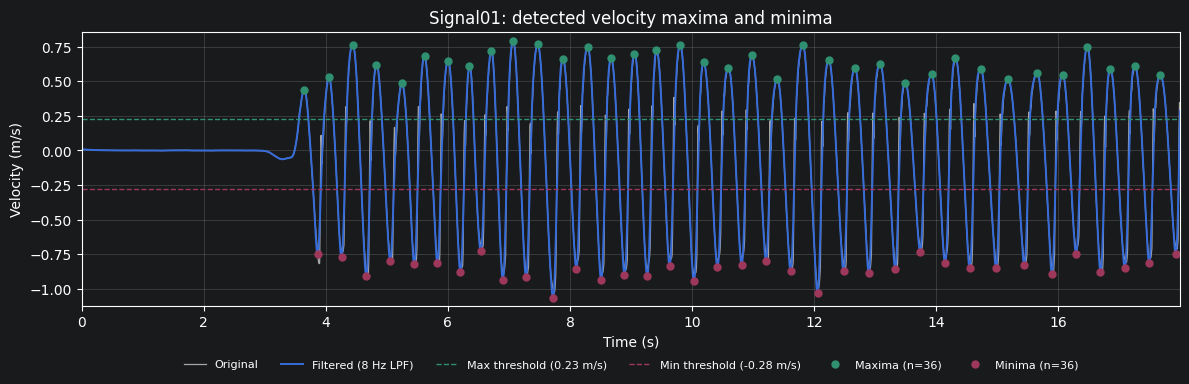

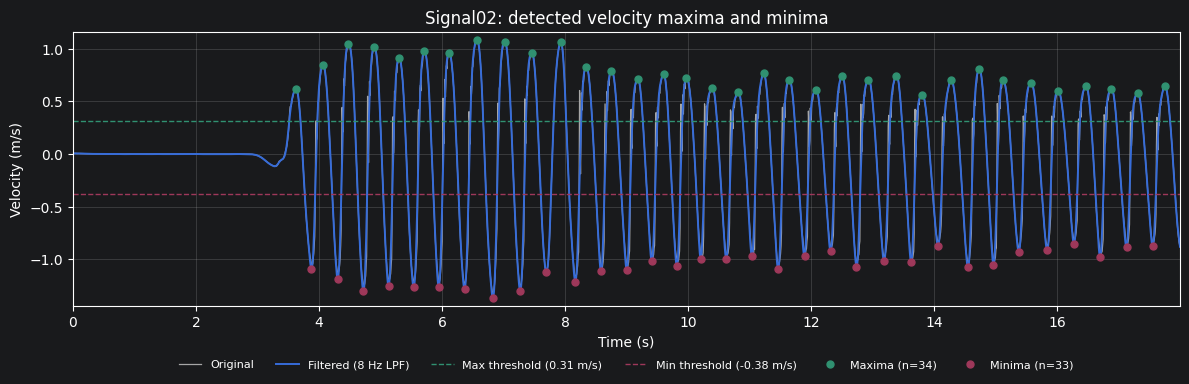

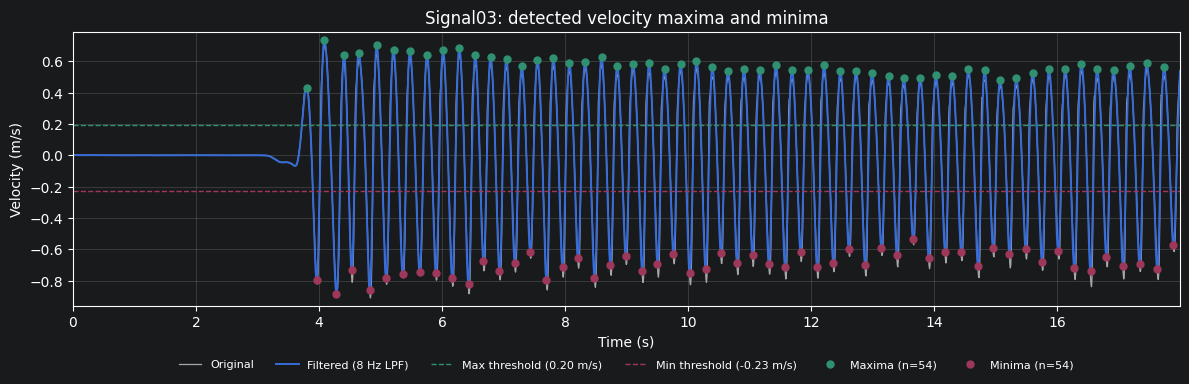

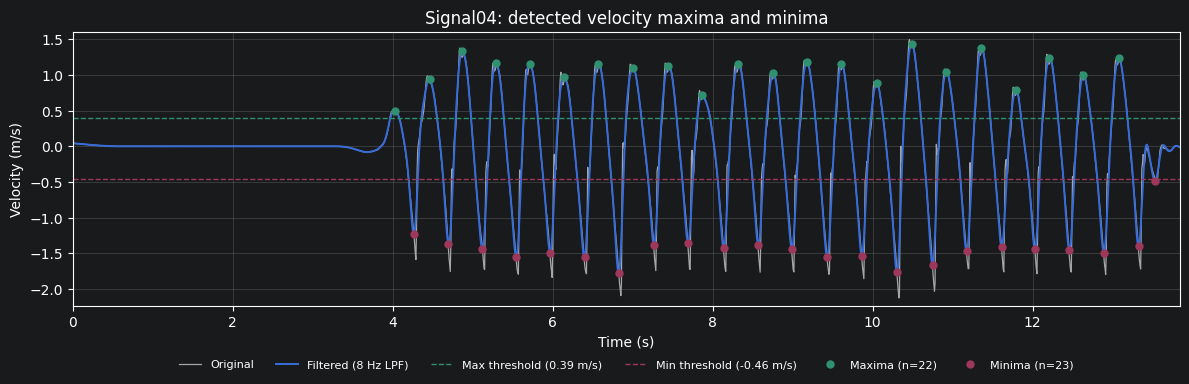

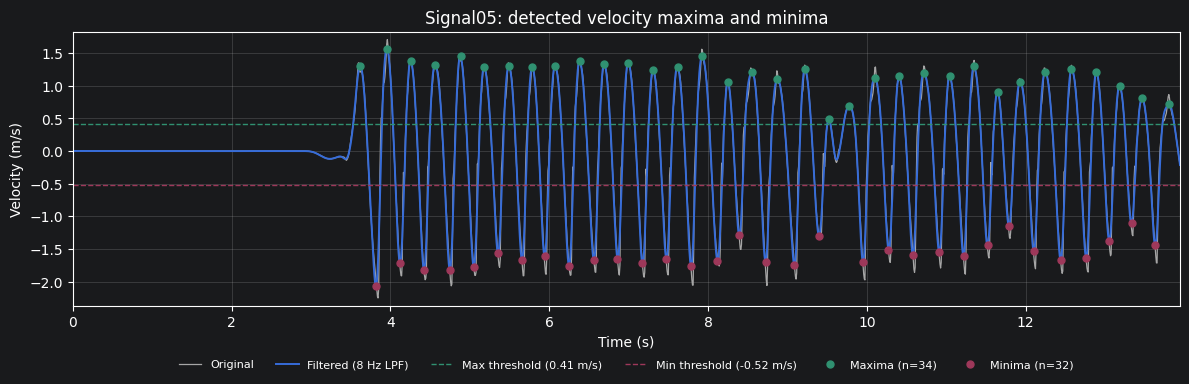

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
fs        = 128.0                  # sample rate (Hz)
data_dir  = os.path.join('.', 'Leg Agility')
files     = [f'Signal0{k}.txt' for k in range(1, 6)]

fc        = 8.0                    # low-pass cutoff (Hz)
order     = 4                      # Butterworth order (effective 8 with filtfilt)
thr_frac  = 0.3                    # threshold = 30% of the 99th / 1st percentile
min_sep_s = 0.20                   # minimum time between two maxima (or two minima), s

# ---------------------------------------------------------------
# Filter design: zero-phase low-pass Butterworth
# ---------------------------------------------------------------
b, a = signal.butter(order, fc / (fs / 2), btype='low')


def detect_extrema(x):
    """Filter x, then return the filtered signal, extrema indices and thresholds."""
    y = signal.filtfilt(b, a, x)                      # zero phase: no time shift of extrema
    thr_max = thr_frac * np.percentile(y, 99)         # positive threshold
    thr_min = thr_frac * np.percentile(y, 1)          # negative threshold
    dist = int(round(min_sep_s * fs))
    i_max, _ = signal.find_peaks( y, height= thr_max, distance=dist)
    i_min, _ = signal.find_peaks(-y, height=-thr_min, distance=dist)
    return y, i_max, i_min, thr_max, thr_min


# ---------------------------------------------------------------
# Run the algorithm on every recording
# ---------------------------------------------------------------
results = {}
for fname in files:
    x = np.loadtxt(os.path.join(data_dir, fname))
    t = np.arange(len(x)) / fs
    y, i_max, i_min, thr_max, thr_min = detect_extrema(x)
    results[fname] = dict(x=x, t=t, y=y, i_max=i_max, i_min=i_min,
                          thr_max=thr_max, thr_min=thr_min)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t, x, color='0.65', lw=0.9, label='Original')
    ax.plot(t, y, color='C0',  lw=1.4, label=f'Filtered ({fc:g} Hz LPF)')
    ax.axhline(thr_max, color='C3', ls='--', lw=1, label=f'Max threshold ({thr_max:.2f} m/s)')
    ax.axhline(thr_min, color='C2', ls='--', lw=1, label=f'Min threshold ({thr_min:.2f} m/s)')
    ax.plot(t[i_max], y[i_max], 'o', color='C3', ms=5, label=f'Maxima (n={len(i_max)})')
    ax.plot(t[i_min], y[i_min], 'o', color='C2', ms=5, label=f'Minima (n={len(i_min)})')

    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    pad = 0.03 * (hi - lo)
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Velocity (m/s)')
    ax.set_title(f'{fname.removesuffix(".txt")}: detected velocity maxima and minima')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=6,
              fontsize=8, frameon=False)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

## Problem 2: Plot the durations of the time intervals of adjacent maxima and adjacent minima. You should find that these time intervals are similar for the maxima and minima in most cases, which should give you confidence that the maxima and minima have been detected accurately.

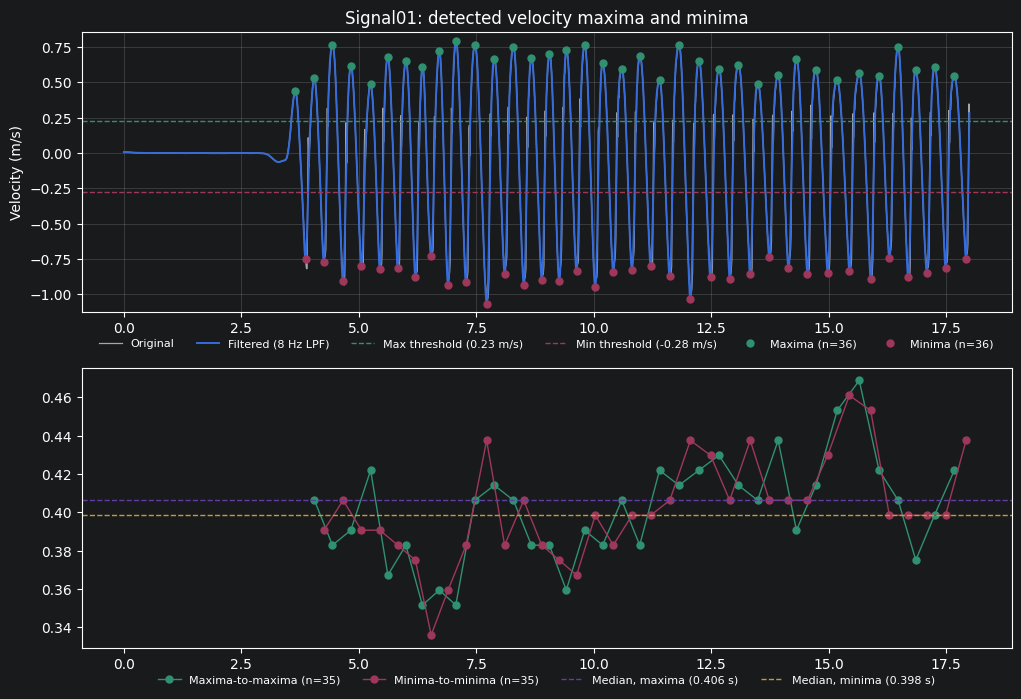

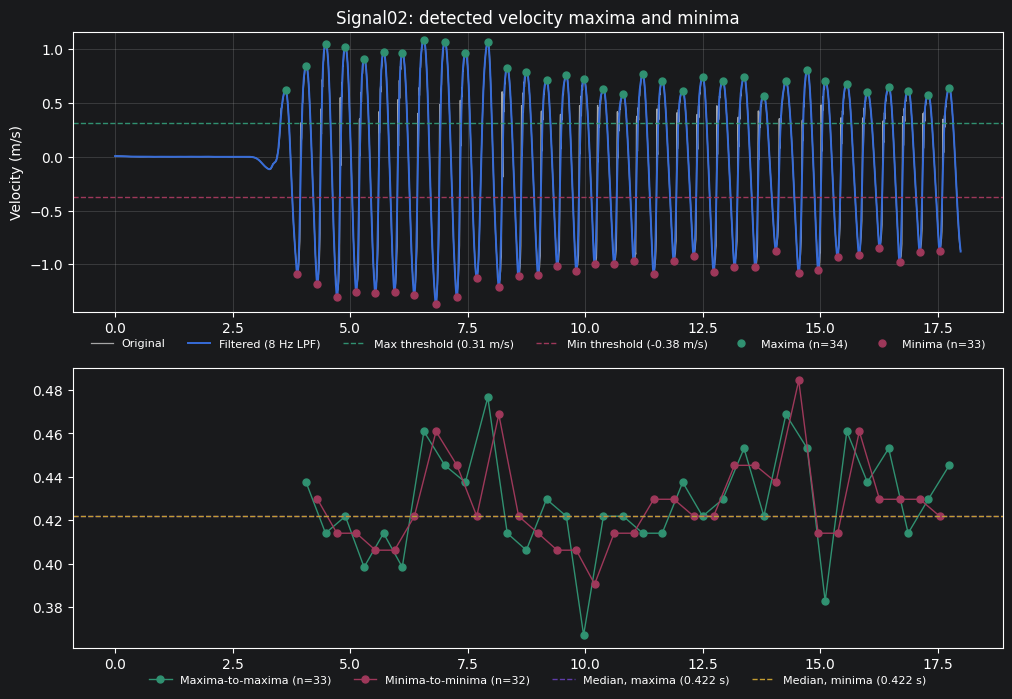

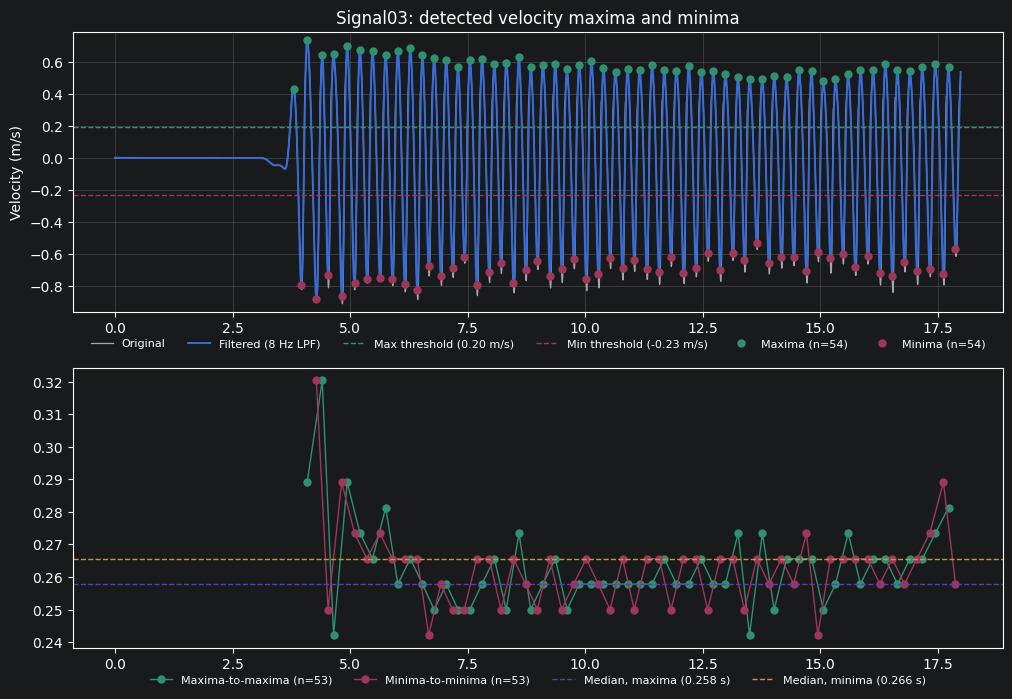

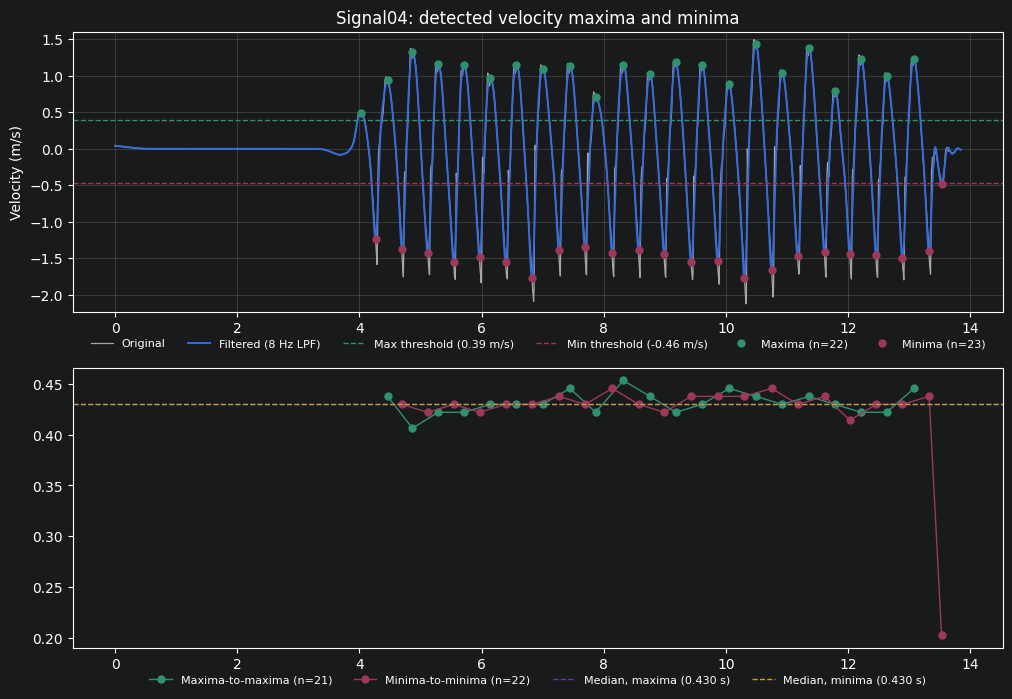

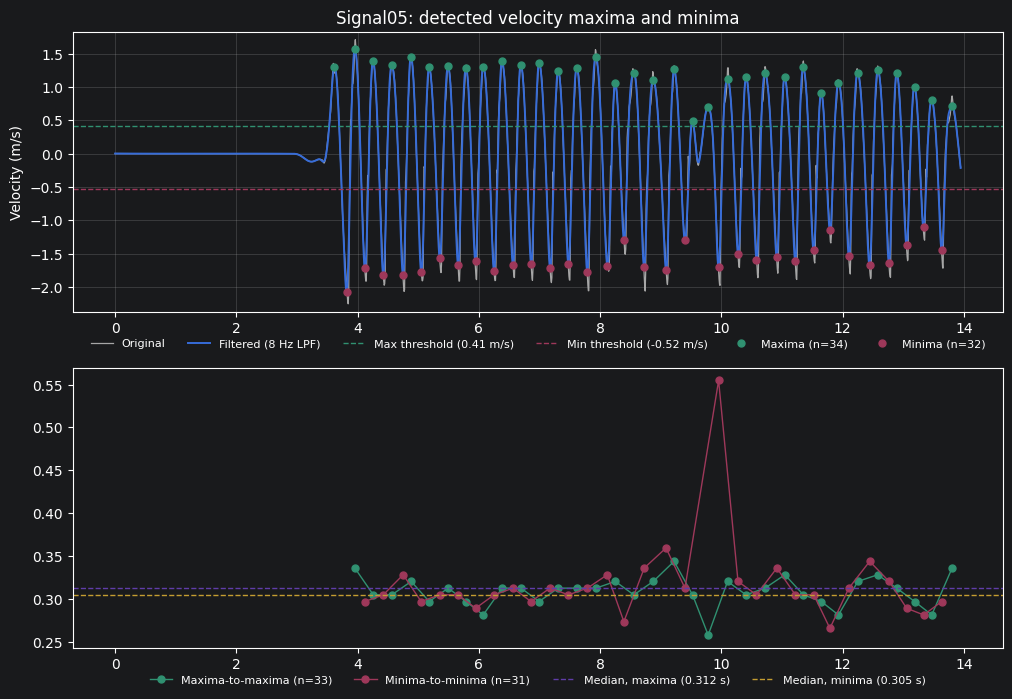

In [12]:
# ---------------------------------------------------------------
# Problem 2: durations between adjacent maxima and adjacent minima
# Uses the `results` dictionary produced by the Problem 1 cell.
# Each figure stacks the Problem 1 detection plot (top) above the
# interval plot (bottom) on a shared time axis.
# ---------------------------------------------------------------
summary2 = []
for fname in files:
    r     = results[fname]
    x, y, t = r['x'], r['y'], r['t']
    i_max, i_min = r['i_max'], r['i_min']
    thr_max, thr_min = r['thr_max'], r['thr_min']
    name = fname.removesuffix('.txt')

    # Interval between each pair of adjacent extrema (s). Each interval is
    # plotted at the time of the second extremum of the pair.
    dT_max = np.diff(i_max) / fs
    dT_min = np.diff(i_min) / fs
    t_max  = t[i_max[1:]]
    t_min  = t[i_min[1:]]

    med_max, med_min = np.median(dT_max), np.median(dT_min)
    summary2.append((name,
                     len(dT_max), dT_max.mean(), dT_max.std(ddof=1), med_max,
                     len(dT_min), dT_min.mean(), dT_min.std(ddof=1), med_min))

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                                   gridspec_kw=dict(height_ratios=[1, 1]))

    # --- Top: Problem 1 detection plot ---
    ax1.plot(t, x, color='0.65', lw=0.9, label='Original')
    ax1.plot(t, y, color='C0',  lw=1.4, label=f'Filtered ({fc:g} Hz LPF)')
    ax1.axhline(thr_max, color='C3', ls='--', lw=1, label=f'Max threshold ({thr_max:.2f} m/s)')
    ax1.axhline(thr_min, color='C2', ls='--', lw=1, label=f'Min threshold ({thr_min:.2f} m/s)')
    ax1.plot(t[i_max], y[i_max], 'o', color='C3', ms=5, label=f'Maxima (n={len(i_max)})')
    ax1.plot(t[i_min], y[i_min], 'o', color='C2', ms=5, label=f'Minima (n={len(i_min)})')
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    pad = 0.03 * (hi - lo)
    ax1.set_ylim(lo - pad, hi + pad)
    ax1.set_ylabel('Velocity (m/s)')
    ax1.set_title(f'{name}: detected velocity maxima and minima')
    ax1.tick_params(labelbottom=True)       # show time labels on the top plot too
    ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=6,
               fontsize=8, frameon=False)
    ax1.grid(alpha=0.3)

    # --- Bottom: intervals between adjacent extrema ---
    ax2.plot(t_max, dT_max, '-o', color='C3', ms=5, lw=1.0,
             label=f'Maxima-to-maxima (n={len(dT_max)})')
    ax2.plot(t_min, dT_min, '-o', color='C2', ms=5, lw=1.0,
             label=f'Minima-to-minima (n={len(dT_min)})')
    ax2.axhline(med_max, color='C4', ls='--', lw=1,
                label=f'Median, maxima ({med_max:.3f} s)')
    ax2.axhline(med_min, color='C5', ls='--', lw=1,
                label=f'Median, minima ({med_min:.3f} s)')
    ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=4,
               fontsize=8, frameon=False)

## Problem 3: Plot the impulse response of your filter

Single pass: sum of h[n]      = 1.0000  (DC gain)
filtfilt   : sum of h_eff[n]  = 1.0000  (DC gain)
filtfilt   : max |h_eff[n] - h_eff[-n]| = 0.00e+00  (symmetric)


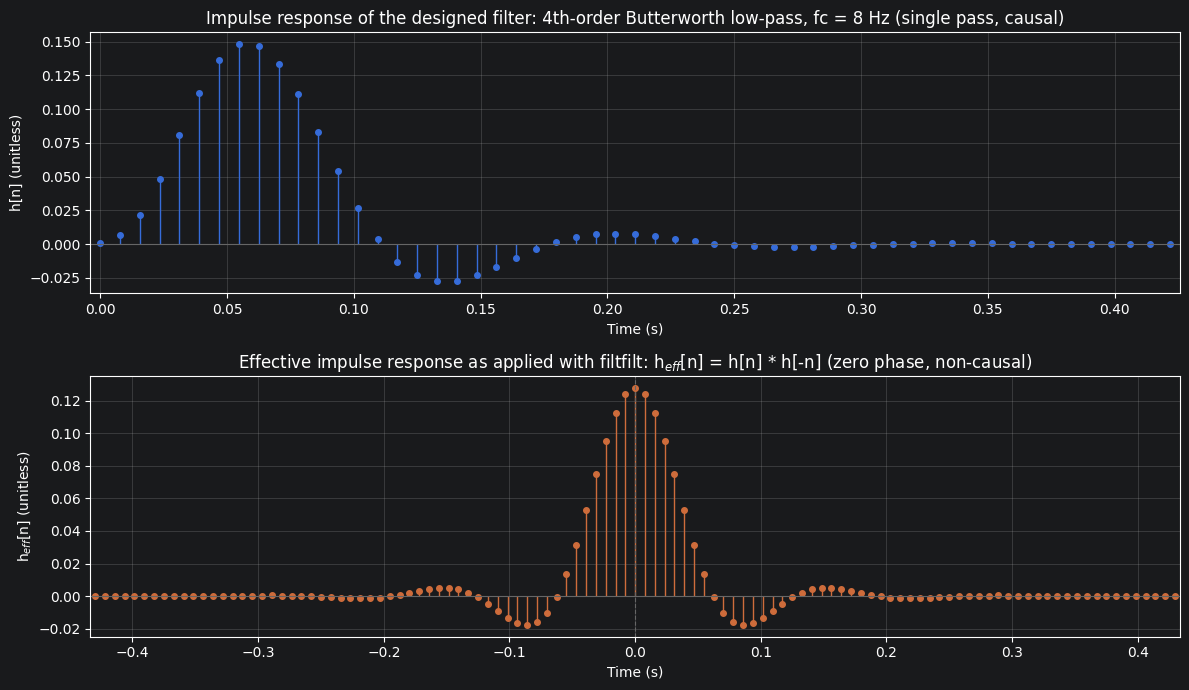

In [14]:
# ---------------------------------------------------------------
# Problem 3: impulse response of the filter
# Uses b, a, fs, fc, order from the Problem 1 cell.
# The designed filter H(z) is a causal 4th-order Butterworth. Because it
# is applied with filtfilt (forward, then backward), the filter actually
# applied to the data has impulse response h_eff[n] = h[n] * h[-n],
# which is symmetric about n = 0 (zero phase, non-causal).
# ---------------------------------------------------------------
N_imp = 128                                    # 1 s of samples, h[n] has decayed to ~0
imp = np.zeros(N_imp); imp[0] = 1.0
h = signal.lfilter(b, a, imp)                  # single-pass impulse response
n_h = np.arange(N_imp)

h_eff = np.convolve(h, h[::-1])                # forward-backward (filtfilt) response
n_eff = np.arange(-(N_imp - 1), N_imp)

print(f'Single pass: sum of h[n]      = {h.sum():.4f}  (DC gain)')
print(f'filtfilt   : sum of h_eff[n]  = {h_eff.sum():.4f}  (DC gain)')
print(f'filtfilt   : max |h_eff[n] - h_eff[-n]| = {np.max(np.abs(h_eff - h_eff[::-1])):.2e}  (symmetric)')

# Plot only the part of each response that is visibly non-zero
tol    = 1e-3 * np.abs(h).max()
n_end  = np.nonzero(np.abs(h) > tol)[0].max() + 2
keep   = np.abs(n_eff) <= n_end

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7))

ml, sl, bl = ax1.stem(n_h[:n_end] / fs, h[:n_end], basefmt=' ')
plt.setp(ml, color='C0', ms=4); plt.setp(sl, color='C0', lw=1)
ax1.axhline(0, color='0.4', lw=0.8)
ax1.set_xlim(-0.5 / fs, (n_end - 0.5) / fs)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('h[n] (unitless)')
ax1.set_title(f'Impulse response of the designed filter: {order}th-order Butterworth '
              f'low-pass, fc = {fc:g} Hz (single pass, causal)')
ax1.grid(alpha=0.3)

ml, sl, bl = ax2.stem(n_eff[keep] / fs, h_eff[keep], basefmt=' ')
plt.setp(ml, color='C1', ms=4); plt.setp(sl, color='C1', lw=1)
ax2.axhline(0, color='0.4', lw=0.8)
ax2.axvline(0, color='0.4', ls='--', lw=0.8)
ax2.set_xlim(-(n_end + 0.5) / fs, (n_end + 0.5) / fs)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('h$_{eff}$[n] (unitless)')
ax2.set_title('Effective impulse response as applied with filtfilt: '
              'h$_{eff}$[n] = h[n] * h[-n] (zero phase, non-causal)')
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Problem 4: Plot the magnitude response of your filter

At fc = 8 Hz      : single pass  -3.01 dB, filtfilt  -6.02 dB
At f95 = 7.44 Hz  : single pass  -1.90 dB, filtfilt  -3.81 dB
At 16 Hz         : single pass  -25.5 dB, filtfilt  -51.0 dB
At 32 Hz         : single pass  -56.1 dB, filtfilt -112.2 dB


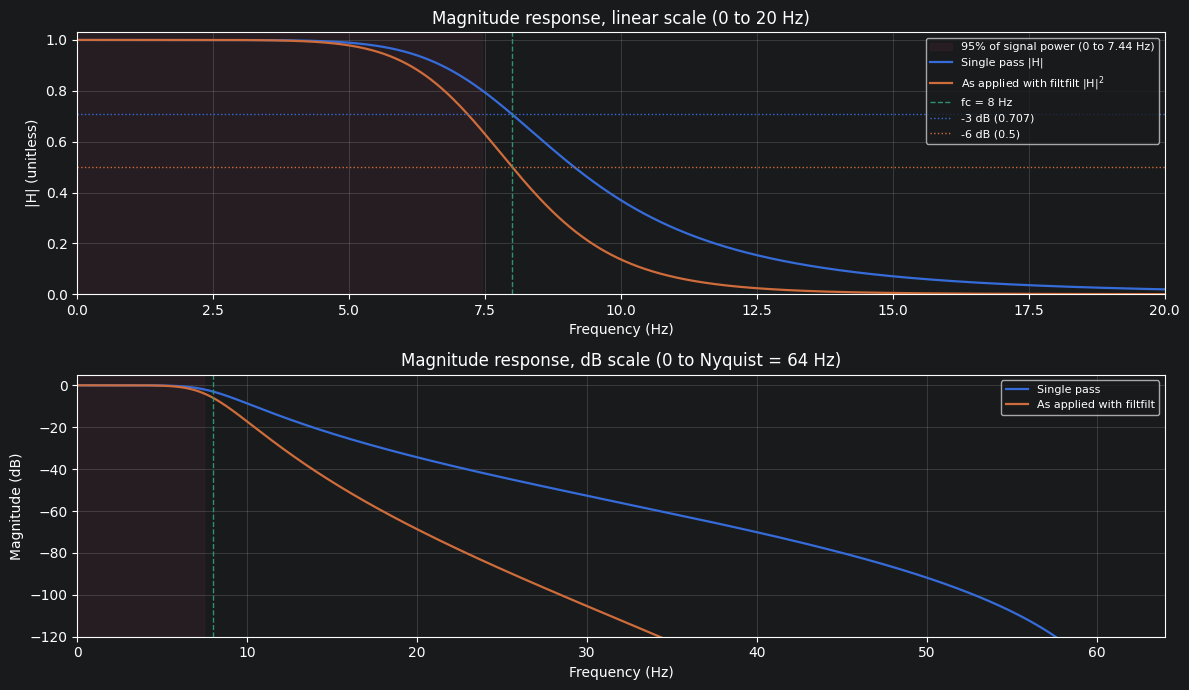

In [17]:
# ---------------------------------------------------------------
# Problem 4: magnitude response of the filter
# Single pass: |H(e^jw)|.  As applied with filtfilt: |H(e^jw)|^2.
# Uses f95_all from the PSD cell to show where the tapping power lies.
# ---------------------------------------------------------------
f_H, H = signal.freqz(b, a, worN=4096, fs=fs)
mag1   = np.abs(H)                             # single pass
mag2   = mag1**2                               # filtfilt
eps    = 1e-12                                 # avoid log(0) at Nyquist
dB1    = 20 * np.log10(mag1 + eps)
dB2    = 20 * np.log10(mag2 + eps)

f_sig  = f95_all.max()                         # highest 95%-power frequency of the 5 signals
k_fc   = np.argmin(np.abs(f_H - fc))
k_sig  = np.argmin(np.abs(f_H - f_sig))
print(f'At fc = {fc:g} Hz      : single pass {dB1[k_fc]:6.2f} dB, filtfilt {dB2[k_fc]:6.2f} dB')
print(f'At f95 = {f_sig:.2f} Hz  : single pass {dB1[k_sig]:6.2f} dB, filtfilt {dB2[k_sig]:6.2f} dB')
for f_chk in (16, 32):
    k = np.argmin(np.abs(f_H - f_chk))
    print(f'At {f_chk:>2} Hz         : single pass {dB1[k]:6.1f} dB, filtfilt {dB2[k]:6.1f} dB')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7))

# --- Top: linear magnitude, zoomed on the passband / transition band ---
f_zoom = 20.0
ax1.axvspan(0, f_sig, color='C2', alpha=0.10,
            label=f'95% of signal power (0 to {f_sig:.2f} Hz)')
ax1.plot(f_H, mag1, color='C0', lw=1.6, label='Single pass |H|')
ax1.plot(f_H, mag2, color='C1', lw=1.6, label='As applied with filtfilt |H|$^2$')
ax1.axvline(fc, color='C3', ls='--', lw=1, label=f'fc = {fc:g} Hz')
ax1.axhline(1 / np.sqrt(2), color='C0', ls=':', lw=1, label='-3 dB (0.707)')
ax1.axhline(0.5, color='C1', ls=':', lw=1, label='-6 dB (0.5)')
ax1.set_xlim(0, f_zoom)
ax1.set_ylim(0, 1.03)
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('|H| (unitless)')
ax1.set_title(f'Magnitude response, linear scale (0 to {f_zoom:g} Hz)')
ax1.legend(loc='upper right', fontsize=8)
ax1.grid(alpha=0.3)

# --- Bottom: magnitude in dB over the full band 0 to fs/2 ---
db_floor = -120
ax2.axvspan(0, f_sig, color='C2', alpha=0.10)
ax2.plot(f_H, dB1, color='C0', lw=1.6, label='Single pass')
ax2.plot(f_H, dB2, color='C1', lw=1.6, label='As applied with filtfilt')
ax2.axvline(fc, color='C3', ls='--', lw=1)
ax2.set_xlim(0, fs / 2)
ax2.set_ylim(db_floor, 5)
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('Magnitude (dB)')
ax2.set_title(f'Magnitude response, dB scale (0 to Nyquist = {fs/2:g} Hz)')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Problem 5: Plot the phase response of your filter

Single-pass group delay: 51.7 ms at 1 Hz, 78.8 ms at 7.44 Hz, peak 79.2 ms at 7.19 Hz
filtfilt group delay   : 0 ms at all frequencies


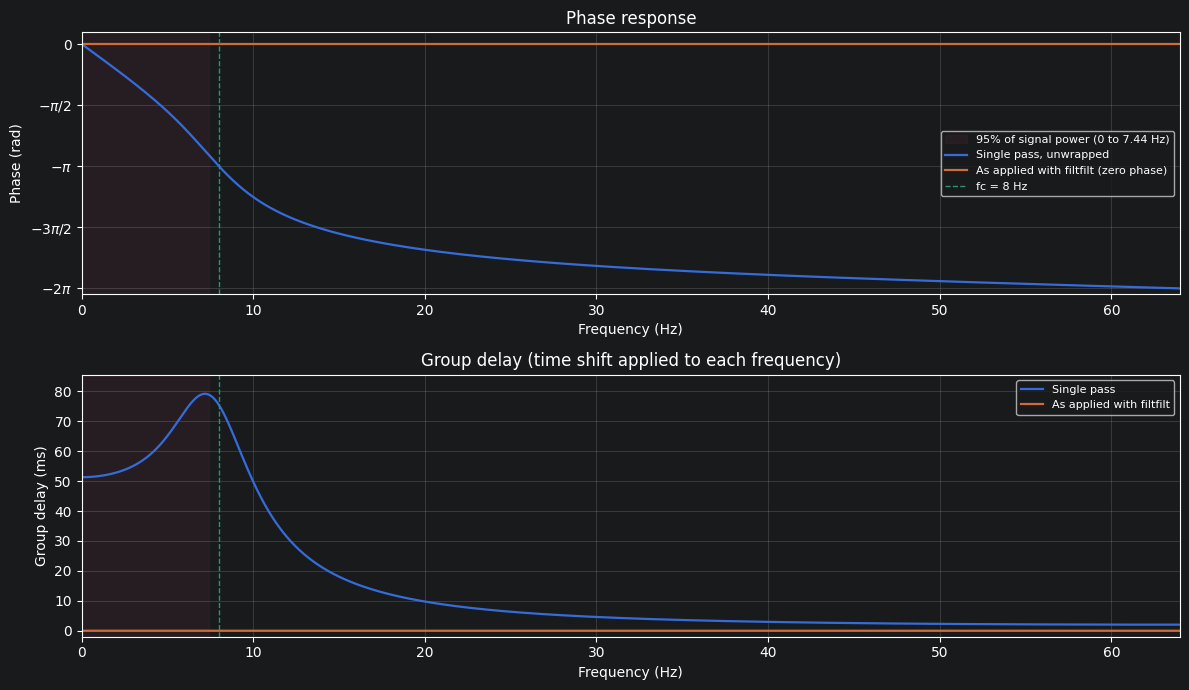

In [16]:
# ---------------------------------------------------------------
# Problem 5: phase response of the filter
# Single pass: angle(H), non-linear, delays the signal.
# As applied with filtfilt: H(e^jw) H*(e^jw) = |H|^2, so the phase is 0.
# Uses f_H, H, f_sig from the Problem 4 cell.
# ---------------------------------------------------------------
phase1 = np.unwrap(np.angle(H))                # single pass (rad)
phase2 = np.zeros_like(phase1)                 # filtfilt (rad)

# Group delay of the single pass = -d(phase)/d(omega), converted to seconds
_, gd_samp = signal.group_delay((b, a), w=f_H, fs=fs)
gd_s = gd_samp / fs
k_lo = np.argmin(np.abs(f_H - 1.0))
k_hi = np.argmin(np.abs(f_H - f_sig))
print(f'Single-pass group delay: {1e3*gd_s[k_lo]:.1f} ms at 1 Hz, '
      f'{1e3*gd_s[k_hi]:.1f} ms at {f_sig:.2f} Hz, '
      f'peak {1e3*gd_s.max():.1f} ms at {f_H[np.argmax(gd_s)]:.2f} Hz')
print('filtfilt group delay   : 0 ms at all frequencies')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax1.axvspan(0, f_sig, color='C2', alpha=0.10,
            label=f'95% of signal power (0 to {f_sig:.2f} Hz)')
ax1.plot(f_H, phase1, color='C0', lw=1.6, label='Single pass, unwrapped')
ax1.plot(f_H, phase2, color='C1', lw=1.6, label='As applied with filtfilt (zero phase)')
ax1.axvline(fc, color='C3', ls='--', lw=1, label=f'fc = {fc:g} Hz')
ax1.set_yticks(np.arange(-2 * np.pi, 0.01, np.pi / 2))
ax1.set_yticklabels([r'$-2\pi$', r'$-3\pi/2$', r'$-\pi$', r'$-\pi/2$', '0'])
ax1.set_ylim(phase1.min() - 0.15, 0.3)
ax1.set_ylabel('Phase (rad)')
ax1.set_title('Phase response')
ax1.tick_params(labelbottom=True)
ax1.set_xlabel('Frequency (Hz)')
ax1.legend(loc='center right', fontsize=8)
ax1.grid(alpha=0.3)

ax2.axvspan(0, f_sig, color='C2', alpha=0.10)
ax2.plot(f_H, 1e3 * gd_s, color='C0', lw=1.6, label='Single pass')
ax2.plot(f_H, np.zeros_like(gd_s), color='C1', lw=1.6, label='As applied with filtfilt')
ax2.axvline(fc, color='C3', ls='--', lw=1)
ax2.set_xlim(0, fs / 2)
ax2.set_ylim(-2, 1e3 * gd_s.max() * 1.08)
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('Group delay (ms)')
ax2.set_title('Group delay (time shift applied to each frequency)')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Problem 6: Fully describe the design of your algorithm and the rationale for all of your design decisions. If your algorithm includes any parameter values such as a cutoff frequency, filter order, or threshold for detection, state these parameters and your rationale for choosing these values.

* Low-Pass Butterworth filter: I wanted to use signal.find_peaks() to identify maxima and minima, so I needed a way to ensure legitimate peaks remained while high-frequency peaks were filtered out.
* 8 Hz cutoff frequency: Cumulative PSD was taken for each signal and the frequency that corresponds to 95% of the signal's power was identified. 7.44 Hz was the highest f95 frequency, so 8 Hz was chosen to make sure every filtered signal got at least 95% of the original signal's power.
* filtfilt: forward and backward passing the signal results in 0 phase delay, which in turn results in 0 group delay. This group delay was desired as I wanted to make sure the maxima and minima peaks of the filtered signal matched the maxima and minima peaks of the original signal.
* Maxima and Minima Thresholds: The 1st and 99th percentile of the signals was multiplied by a shared fraction. This adaptable threshold allowed the creation of a singular algorithm for all 5 signals. Through experimentation, 30% of the 1st and 99th percentile was chosen as it captured most of the maxima and minima.

## Problem 7: What, if anything, did you learn from this homework?

* Using the cumulative PSD to determine the f95 frequency.
* Using time-duration plots to ensure maxima-minima plots are accurate.

Not learned, but confirmed graphically:
* filtfilt processing 2x the order of the original filter.

## Problem 8: What new questions, if any, do you have?

No new questions at this time.